# 01 EDA and preprocessing

This notebook explores the anime data and prepares the final dataset that the rest of the project uses.

**The data.** The dataset combines two public MyAnimeList sources. Ratings, user attributes and timestamps come from the 2018 MyAnimeList Dataset [1]. Synopsis text comes from the 2020 Anime Recommendation Database [2]. No single source had all four kinds of data the project needs, so the synopsis was joined to the 2018 data on the anime ID. The merge is done in `00_build_dataset.ipynb`. It keeps every interaction and gives a synopsis to 99.1% of them.

**What this notebook does**

1. Basic checks on size, missing values, duplicates and invalid values
2. EDA of the feedback, the context (time), the anime and the users
3. Preprocessing, where each cleaning decision is based on a result from the EDA
4. A sample of users for modelling, saved to `data/processed`

In the anime lists, each row is one user and one anime. `score` is the rating from 1 to 10, where 0 means the user did not rate it. `status` is where the anime is on the user's list. The codes are 1 watching, 2 completed, 3 on hold, 4 dropped and 6 plan to watch.

In [1]:
%pip install -q pandas pyarrow matplotlib pycountry

Note: you may need to restart the kernel to use updated packages.


In [2]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pycountry

MERGED_DIR = "../data/merged"
PROCESSED_DIR = "../data/processed"

my_seed = 1234
np.random.seed(my_seed)

## 1. Load the data

The interactions table has 31 million rows. To keep it small enough for a laptop, it is loaded one file at a time and the number columns are stored as smaller types. A score from 0 to 10 does not need 64 bits.

In [3]:
SMALL_TYPES = {
    "user_id": "int32",
    "anime_id": "int32",
    "score": "int8",
    "status": "int8",
    "watched_episodes": "int32",
}

def load_interactions(columns):
    parts = []
    for path in sorted(glob.glob(os.path.join(MERGED_DIR, "interactions", "*.parquet"))):
        part = pd.read_parquet(path, columns=columns)
        part = part.astype({col: SMALL_TYPES[col] for col in columns if col in SMALL_TYPES})
        parts.append(part)
    return pd.concat(parts, ignore_index=True)

interactions_df = load_interactions(
    ["user_id", "anime_id", "score", "status", "watched_episodes", "last_updated"]
)
anime_df = pd.read_parquet(os.path.join(MERGED_DIR, "anime.parquet"))
users_df = pd.read_parquet(os.path.join(MERGED_DIR, "users.parquet"))

print(f"Memory used by the interactions: {interactions_df.memory_usage().sum() / 1e9:.2f} GB")
interactions_df.head()

Memory used by the interactions: 0.69 GB


,user_id,anime_id,score,status,watched_episodes,last_updated
0,2255153,21,9,1,586,2013-03-03 10:52:53
1,2255153,59,7,2,26,2013-03-10 13:54:51
2,2255153,74,7,2,26,2013-04-27 16:43:35
3,2255153,120,7,2,26,2013-03-03 10:53:57
4,2255153,178,7,2,26,2013-03-27 15:59:13


## 2. Basic checks

In [4]:
def basic_stats(df, user_col, item_col):
    n_rows = df.shape[0]
    n_users = df[user_col].nunique()
    n_items = df[item_col].nunique()
    print(f"There are {n_rows} interactions from {n_users} users to {n_items} anime")
    return n_rows, n_users, n_items

basic_stats(interactions_df, "user_id", "anime_id");

There are 31284030 interactions from 108710 users to 6668 anime


In [5]:
# One number per user and anime pair (anime ids are below 100,000), which uses less memory than comparing two columns
pair_key = interactions_df["user_id"].astype("int64") * 100_000 + interactions_df["anime_id"]
print("Duplicate user and anime pairs:", pair_key.duplicated().sum())
del pair_key
print()
print("Share of missing values in the interactions")
print(interactions_df.isna().mean().round(3))

Duplicate user and anime pairs: 0

Share of missing values in the interactions
user_id             0.0
anime_id            0.0
score               0.0
status              0.0
watched_episodes    0.0
last_updated        0.0
dtype: float64


In [6]:
# start_date and finish_date are only loaded here to see how often they are filled
dates_df = load_interactions(["start_date", "finish_date"])
print("Share of missing start_date:", round(dates_df["start_date"].isna().mean(), 3))
print("Share of missing finish_date:", round(dates_df["finish_date"].isna().mean(), 3))
del dates_df

Share of missing start_date: 0.85
Share of missing finish_date: 0.816


There are no duplicate user and anime pairs and no missing values in the columns that are used. `start_date` and `finish_date` are missing in 85% and 82% of the rows, because most users never fill them in. They are too sparse to use as context, so `last_updated` is the timestamp used in the rest of the project.

In [7]:
print("Missing values in the anime table")
print(anime_df.isna().sum())

Missing values in the anime table
anime_id              0
title                 0
title_english      3230
type                  0
source                0
episodes              0
rating               82
score                 0
scored_by             0
popularity            0
members               0
premiered          3702
studio                0
genre                 4
duration_min          0
aired_from_year       0
synopsis            345
dtype: int64


Only four anime have no genre. 345 anime (5.2%) have no synopsis because they had no match in the 2020 source. They stay in the catalog, since a content-based model can still describe them with title, genre and type. `title_english` and `premiered` are often empty but are not needed.

In [8]:
print("Missing values in the users table")
print(users_df.isna().sum())

Missing values in the users table
user_id       0
gender        0
location      5
birth_date    0
join_date     0
dtype: int64


### Status values

In [9]:
interactions_df["status"].value_counts().sort_index()

status
0          167
1      1558384
2     19946276
3      1186648
4      1230250
5            4
6      7362297
33           3
55           1
Name: count, dtype: int64

Codes 0, 5, 33 and 55 are not valid MyAnimeList statuses. They appear in 175 rows, which is too few to matter, so these rows are removed in the preprocessing. The other codes show that most entries are completed anime (64%), followed by plan to watch (24%).

### Dates

First last_updated: 1970-01-01 00:00:00
Last last_updated: 2018-05-22 07:49:06


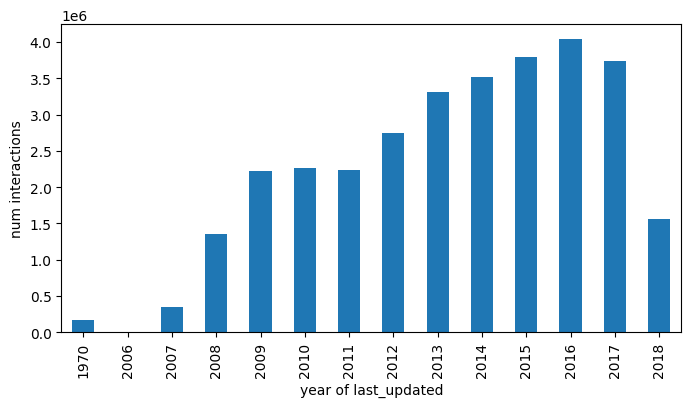

In [10]:
print("First last_updated:", interactions_df["last_updated"].min())
print("Last last_updated:", interactions_df["last_updated"].max())

plt.figure(figsize=(8, 4))
interactions_df.groupby(interactions_df["last_updated"].dt.year).size().plot.bar();
plt.xlabel("year of last_updated");
plt.ylabel("num interactions");

The data runs from 2006 to May 2018, so 2018 only covers five months. 163,231 rows (0.5%) have the date 1970-01-01. This is the start of Unix time and the usual sign of a missing timestamp, not a real date. These rows would break a split by time, so they are removed in the preprocessing.

## 3. EDA of the feedback
### Explicit and implicit feedback

Share of interactions without a score: 0.387


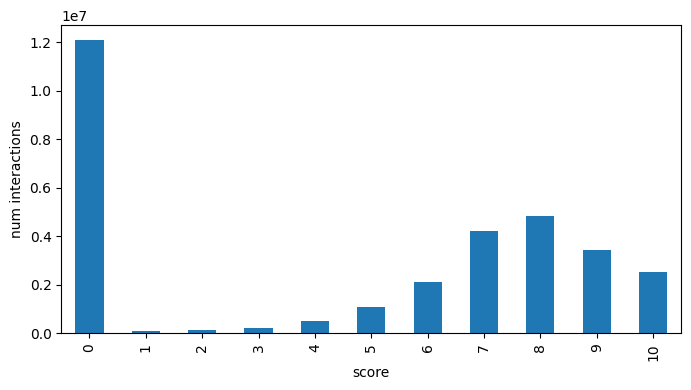

In [11]:
plt.figure(figsize=(8, 4))
interactions_df.groupby("score").size().plot.bar();
plt.ylabel("num interactions");

print(f"Share of interactions without a score: {(interactions_df['score'] == 0).mean():.3f}")

In [12]:
status_names = {1: "watching", 2: "completed", 3: "on hold", 4: "dropped", 6: "plan to watch"}
rated_share = (interactions_df["score"] > 0).groupby(interactions_df["status"]).mean()
rated_share = rated_share[rated_share.index.isin(status_names.keys())]
rated_share.index = rated_share.index.map(status_names)
print("Share of interactions with a score, per status")
print(rated_share.round(3))

Share of interactions with a score, per status
status
watching         0.352
completed        0.876
on hold          0.354
dropped          0.513
plan to watch    0.014
Name: score, dtype: float64


39% of the interactions have no score. Whether a user gives a score depends on the status. 88% of completed anime have a score but only 1.4% of plan to watch entries do. This means the data has two kinds of feedback. The score is explicit feedback, which is a clear opinion but only exists when the user makes the effort to rate. The status is implicit feedback. Adding an anime to the list already shows interest, even without a score [3][4]. Plan to watch is the weakest signal, since the user has not watched the anime yet.

For the explicit ratings below, only rows with a score from 1 to 10 are used, and plan to watch is left out because a user cannot rate something they have not seen.

### Ratings

In [13]:
ratings_df = interactions_df[(interactions_df["score"] > 0) & (interactions_df["status"] != 6)]
n_ratings, n_users, n_items = basic_stats(ratings_df, "user_id", "anime_id")

print(f"Mean rating: {ratings_df['score'].mean():.2f}")
print(f"Median rating: {ratings_df['score'].median():.0f}")

There are 19066725 interactions from 106377 users to 6596 anime
Mean rating: 7.59
Median rating: 8


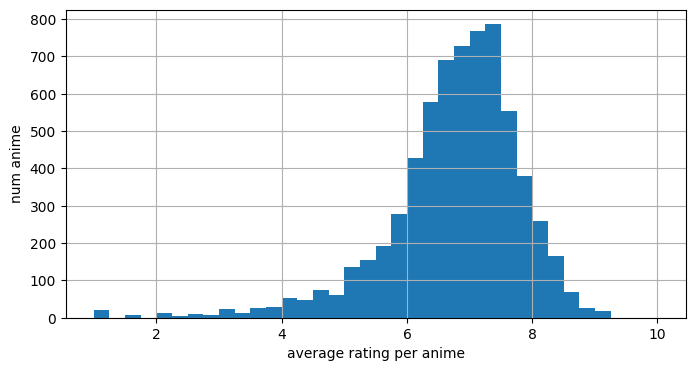

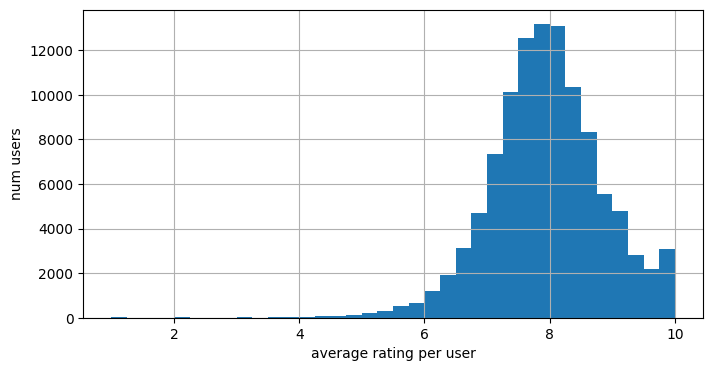

In [14]:
plt.figure(figsize=(8, 4))
ratings_df.groupby("anime_id")["score"].mean().hist(bins=np.arange(1, 10.25, 0.25));
plt.xlabel("average rating per anime");
plt.ylabel("num anime");

plt.figure(figsize=(8, 4))
ratings_df.groupby("user_id")["score"].mean().hist(bins=np.arange(1, 10.25, 0.25));
plt.xlabel("average rating per user");
plt.ylabel("num users");

The ratings are very positive. The mean is 7.59 and the median is 8, and scores from 1 to 4 together are under 5% of all ratings. Users mostly add anime they expect to like, so the bad ratings that would exist for random anime are missing from the data [3]. For the models this means the difference between a 7 and an 8 carries most of the information, and an RMSE close to 1 is already a small error on this scale.

The average per user is centred around 7.9, but some users rate everything 10 and others are much stricter. This user bias is something collaborative filtering has to correct for. The average per anime has a long left side. Anime with fewer than 50 ratings have an average of 5.45, while anime with at least 1,000 ratings average 7.32. Rare anime are rated by fewer and less typical users, so their averages are less reliable.

### Long tail and sparsity

The 20% most rated anime have 74.9% of all ratings
count     6596.0
mean      2891.0
std       5388.0
min          1.0
25%        155.0
50%        789.0
75%       3131.0
max      68743.0
dtype: float64


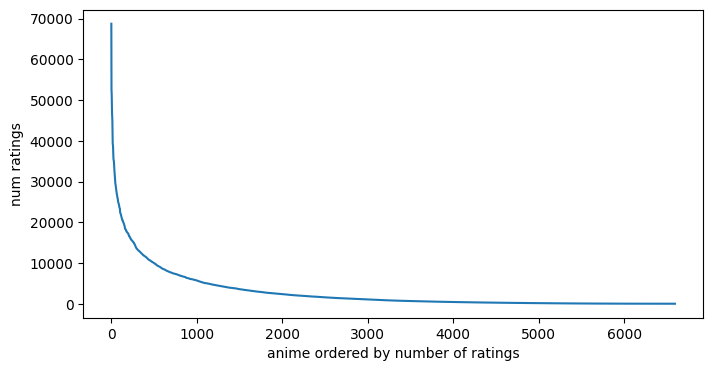

In [15]:
ratings_per_anime = ratings_df.groupby("anime_id").size().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
plt.plot(range(len(ratings_per_anime)), ratings_per_anime.values);
plt.xlabel("anime ordered by number of ratings");
plt.ylabel("num ratings");

top_20_share = ratings_per_anime.iloc[: int(len(ratings_per_anime) * 0.2)].sum() / ratings_per_anime.sum()
print(f"The 20% most rated anime have {top_20_share:.1%} of all ratings")
print(ratings_per_anime.describe().round(0))

The ratings follow a strong long tail. The 20% most rated anime receive 74.9% of all ratings, while half of the anime have fewer than 789 ratings. Aggarwal [3] describes three consequences. Popular items are easy to recommend but give the user little new. Predictions for items in the tail are harder because there is little data about them. And many algorithms drift towards popular items, which lowers coverage and diversity. This is why coverage and diversity are measured next to accuracy in this project.

count    106377.0
mean        179.0
std         213.0
min           1.0
25%          44.0
50%         113.0
75%         236.0
max        3785.0
dtype: float64
Users with fewer than 10 ratings: 8077


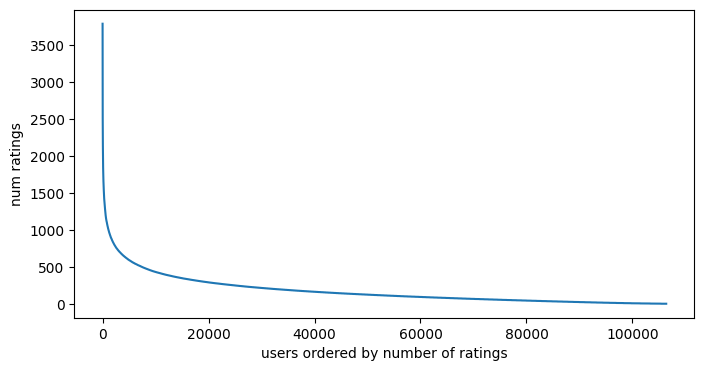

In [16]:
ratings_per_user = ratings_df.groupby("user_id").size().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
plt.plot(range(len(ratings_per_user)), ratings_per_user.values);
plt.xlabel("users ordered by number of ratings");
plt.ylabel("num ratings");

print(ratings_per_user.describe().round(0))
print("Users with fewer than 10 ratings:", (ratings_per_user < 10).sum())

User activity is also skewed. The median user has 113 ratings, but the most active user has 3,785. 8,077 users have fewer than 10 ratings, which is too few to evaluate them properly after a train and test split. They behave almost like new users.

In [17]:
sparsity = 1 - n_ratings / (n_users * n_items)
print(f"The user-anime rating matrix is {sparsity:.2%} empty")

The user-anime rating matrix is 97.28% empty


97.28% of the user and anime matrix is empty. This is less sparse than most e-commerce data, because the catalog is small (6,596 rated anime) and users on MyAnimeList keep long lists. It is still sparse enough that two random users have few anime in common, which is the main difficulty for memory-based collaborative filtering.

## 4. EDA of the context

`last_updated` is the only timestamp that is always filled. It is the moment the user last changed the entry. The fake 1970 dates are left out of these plots.

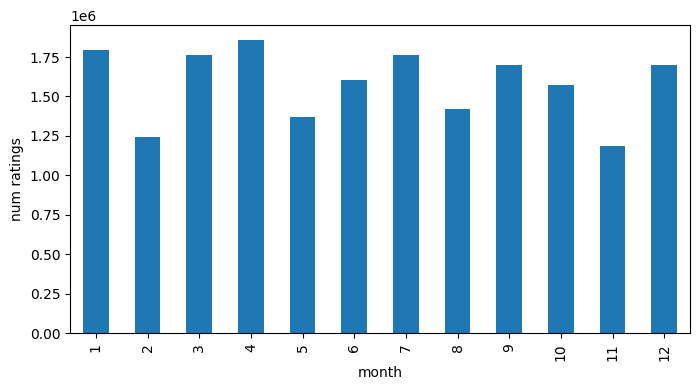

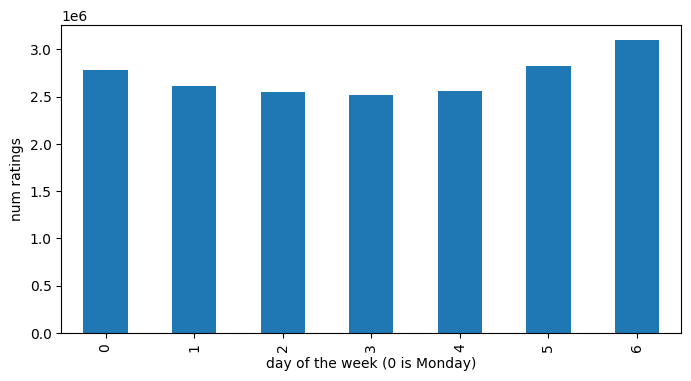

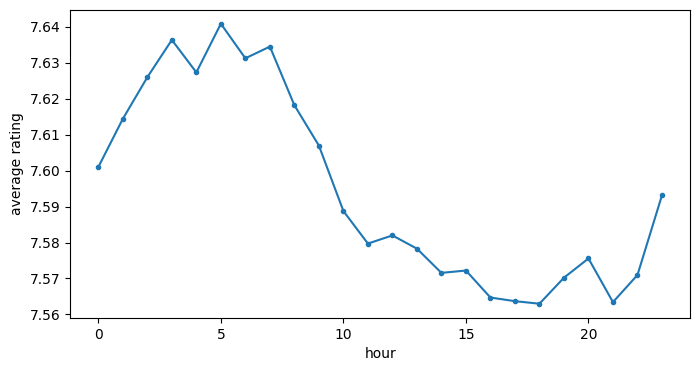

In [18]:
real_dates = ratings_df.loc[ratings_df["last_updated"].dt.year > 1970, ["last_updated", "score"]]

plt.figure(figsize=(8, 4))
real_dates.groupby(real_dates["last_updated"].dt.month).size().plot.bar();
plt.xlabel("month");
plt.ylabel("num ratings");

plt.figure(figsize=(8, 4))
real_dates.groupby(real_dates["last_updated"].dt.dayofweek).size().plot.bar();
plt.xlabel("day of the week (0 is Monday)");
plt.ylabel("num ratings");

plt.figure(figsize=(8, 4))
real_dates.groupby(real_dates["last_updated"].dt.hour)["score"].mean().plot(marker=".");
plt.xlabel("hour");
plt.ylabel("average rating");

There is no strong pattern by month, apart from fewer updates in February, May, August and November. Updates are spread over the week with a small peak on Sunday. The average rating hardly changes with the hour of the day (from 7.56 to 7.64). The time zone of `last_updated` is not known, so the hour should be read with care.

These results suggest that simple time context like hour or weekday will not change the ratings much. Context-aware models are more likely to gain from the year, since tastes and the catalog change over time, and from a split by time, which is closer to how the system would be used in reality.

## 5. EDA of the anime

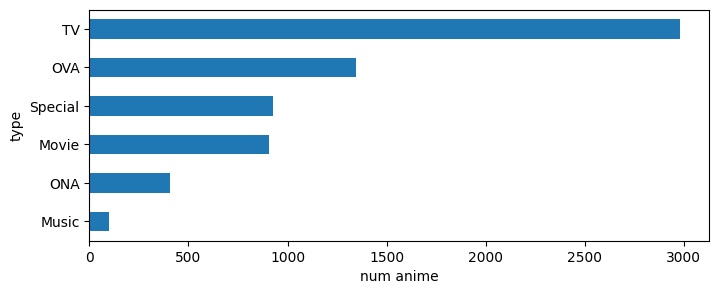

In [19]:
anime_df.groupby("type").size().sort_values().plot.barh(figsize=(8, 3));
plt.xlabel("num anime");

Number of different genres: 43
Average number of genres per anime: 3.6


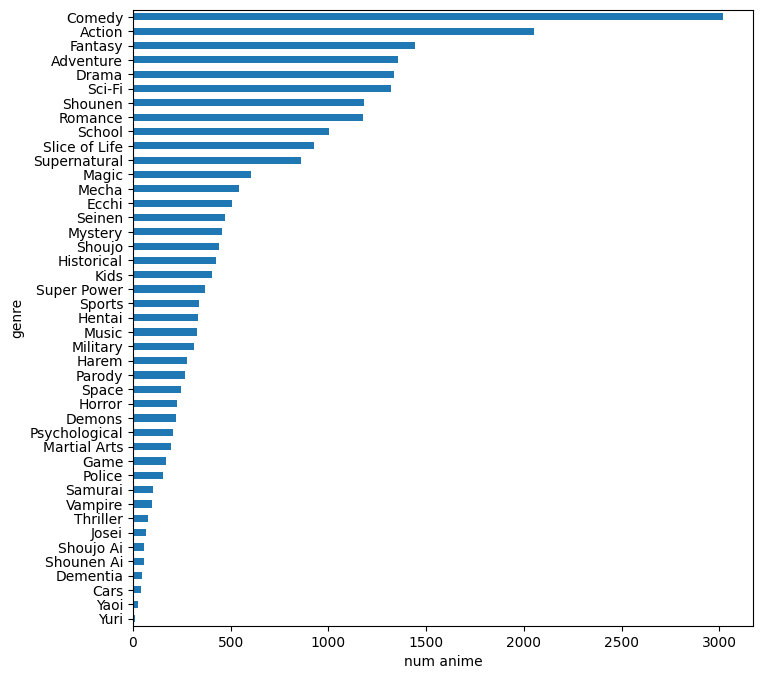

In [20]:
genres = anime_df["genre"].dropna().str.split(", ").explode()

plt.figure(figsize=(8, 8))
genres.value_counts().sort_values().plot.barh();
plt.xlabel("num anime");

print("Number of different genres:", genres.nunique())
print("Average number of genres per anime:", round(anime_df["genre"].dropna().str.split(", ").str.len().mean(), 1))

There are 43 genres and each anime has 3.6 on average. Comedy and Action are the most common. The genres are useful item features for content-based models and for measuring diversity. TV series are the largest type (2,980), followed by OVA, specials and movies.

count    6323.0
mean       88.0
std        62.0
min         2.0
25%        33.0
50%        80.0
75%       137.0
max       487.0
Name: synopsis, dtype: float64

2144    Ever since he was a child, zombie-obsessed Chi...
904     usic video included with the debut single for ...
5957    In Japanese folklore, a "tsukumogami" is an ob...


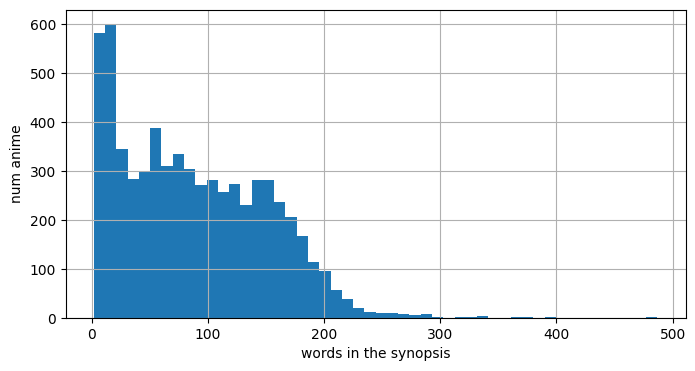

In [21]:
synopsis_words = anime_df["synopsis"].dropna().str.split().str.len()

plt.figure(figsize=(8, 4))
synopsis_words.hist(bins=50);
plt.xlabel("words in the synopsis");
plt.ylabel("num anime");

print(synopsis_words.describe().round(0))
print()
print(anime_df["synopsis"].dropna().sample(3, random_state=my_seed).str[:300].to_string())

A synopsis has 80 words at the median, which is enough text for TF-IDF and BERT. 1,105 synopses have fewer than 20 words, though. Many of these are sequels or specials described only in relation to another title, like "Second season of Sekaiichi Hatsukoi". Some also start in the middle of a word, like the second example above. For these anime the synopsis says little, so a content-based model should also use the title and genres.

## 6. EDA of the users

gender
Male          70880
Female        37330
Non-Binary      501
Name: count, dtype: int64
count    108711.0
mean         25.0
std           4.6
min           9.4
25%          21.8
50%          24.7
75%          27.8
max          49.4
Name: birth_date, dtype: float64


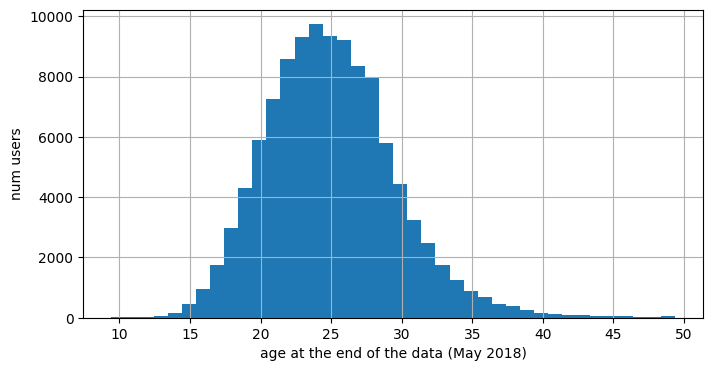

In [22]:
print(users_df["gender"].value_counts())

end_of_data = interactions_df["last_updated"].max()
age = (end_of_data - users_df["birth_date"]).dt.days / 365.25

plt.figure(figsize=(8, 4))
age.hist(bins=40);
plt.xlabel("age at the end of the data (May 2018)");
plt.ylabel("num users");

print(age.describe().round(1))

Two thirds of the users are male, one third female and 501 non-binary. The users are young. The median age at the end of the data is 24.7 years and almost all users are between 15 and 38. All ages are between 9 and 49, so there are no impossible birth dates to correct. Age and gender can be used directly for demographic filtering.

In [23]:
last_part = users_df["location"].str.split(",").str[-1].str.strip()

print("Different values after the last comma:", last_part.nunique())
print(last_part.value_counts().head(25))

Different values after the last comma: 20060
location
Poland         3562
California     2731
Canada         2272
Brazil         2143
Germany        2084
Philippines    2000
Australia      1625
Russia         1562
Brasil         1490
France         1482
England        1433
Portugal       1407
Indonesia      1370
Texas          1227
Sweden         1217
Florida         996
New York        995
UK              954
Finland         930
Italy           930
USA             927
Norway          851
Romania         781
Netherlands     748
Spain           745
Name: count, dtype: int64


Location is free text written by the users. After the last comma there are 20,060 different values. Countries, US states, cities, abbreviations and spelling variants are all mixed, such as Brazil and Brasil or UK and England. This column cannot be used for demographic filtering as it is, so it is cleaned into a country in the preprocessing.

## 7. Preprocessing

Each step below fixes a problem that the EDA showed. The number of rows is printed after each step so the effect of every decision is visible.

In [24]:
# The EDA tables are no longer needed, so they are removed to free memory
del ratings_df, real_dates

invalid_status = ~interactions_df["status"].isin(status_names.keys())
fake_date = interactions_df["last_updated"].dt.year == 1970

print("Interactions with an invalid status code:", invalid_status.sum())
print("Interactions with the fake 1970 date:", fake_date.sum())

clean_df = interactions_df[~invalid_status & ~fake_date]
print("Interactions left:", len(clean_df))
del interactions_df, invalid_status, fake_date

Interactions with an invalid status code: 175
Interactions with the fake 1970 date: 163231


Interactions left: 31120705


Rows with an invalid status code are removed for the reason given in the status check. Rows with the 1970 date are removed for the reason given in the date check. Together this is 0.5% of the data.

In [25]:
plan_to_watch_with_score = (clean_df["status"] == 6) & (clean_df["score"] > 0)
print("Plan to watch entries with a score:", plan_to_watch_with_score.sum())

clean_df.loc[plan_to_watch_with_score, "score"] = 0

Plan to watch entries with a score: 104667


These scores are set to 0 (not rated) instead of removing the rows. The user cannot have an opinion about an anime they have not watched, so the score is not a real rating. The entry itself is still useful as implicit feedback. After this step there is one simple rule for the whole project. A row is an explicit rating when `score` is above 0.

### Users: country and age

In [26]:
country_names = {}
for country in pycountry.countries:
    country_names[country.name.lower()] = getattr(country, "common_name", country.name)

us_states = [state.name.lower() for state in pycountry.subdivisions.get(country_code="US")]

# Common spellings, cities and regions that do not match an official country name
aliases = {
    "usa": "United States", "us": "United States", "america": "United States",
    "united states of america": "United States",
    "uk": "United Kingdom", "england": "United Kingdom", "scotland": "United Kingdom",
    "wales": "United Kingdom", "great britain": "United Kingdom", "london": "United Kingdom",
    "brasil": "Brazil", "são paulo": "Brazil", "rio de janeiro": "Brazil", "minas gerais": "Brazil",
    "russia": "Russian Federation", "moscow": "Russian Federation", "saint-petersburg": "Russian Federation",
    "the netherlands": "Netherlands", "holland": "Netherlands", "nederland": "Netherlands",
    "polska": "Poland", "warsaw": "Poland",
    "españa": "Spain", "barcelona": "Spain", "madrid": "Spain",
    "méxico": "Mexico", "italia": "Italy", "deutschland": "Germany",
    "turkey": "Türkiye", "istanbul": "Türkiye", "czech republic": "Czechia",
    "ontario": "Canada", "alberta": "Canada", "quebec": "Canada", "british columbia": "Canada", "toronto": "Canada",
    "uae": "United Arab Emirates", "south korea": "Korea, Republic of", "korea": "Korea, Republic of",
    "vietnam": "Viet Nam", "jakarta": "Indonesia", "manila": "Philippines", "tokyo": "Japan",
    "sydney": "Australia", "melbourne": "Australia", "paris": "France",
}

def clean_country(location):
    last = str(location).split(",")[-1].strip().lower()
    if last in aliases:
        return aliases[last]
    if last in country_names:
        return country_names[last]
    if last in us_states:
        return "United States"
    return "Unknown"

users_df["country"] = users_df["location"].apply(clean_country)
print(f"Share of users with a recognised country: {(users_df['country'] != 'Unknown').mean():.3f}")

Share of users with a recognised country: 0.642


In [27]:
MIN_USERS_PER_COUNTRY = 200

country_counts = users_df["country"].value_counts()
small_countries = country_counts[country_counts < MIN_USERS_PER_COUNTRY].index
users_df.loc[users_df["country"].isin(small_countries), "country"] = "Other"

print(users_df["country"].value_counts())

country
Unknown               38938
United States         16632
Brazil                 4633
Poland                 4080
United Kingdom         3958
Other                  3652
Canada                 3578
Philippines            2397
Russian Federation     2202
Germany                2158
Australia              1927
Netherlands            1826
France                 1698
Indonesia              1676
Portugal               1441
Sweden                 1273
Spain                  1199
Italy                  1095
Finland                 945
Norway                  878
Romania                 798
Japan                   733
India                   709
Singapore               699
Türkiye                 658
Malaysia                645
Hungary                 594
Bulgaria                587
Belgium                 568
Greece                  527
Denmark                 501
Argentina               478
Mexico                  470
Lithuania               439
Georgia                 437
New Zealand 

Each location is matched to a country through the official country list, a list of US states and a short list of common spellings and cities. This gives a country for 64% of the users. The rest is too vague to match, like "Earth" or "Wonderland", and becomes Unknown. Countries with fewer than 200 users are grouped as Other, so that every country group has enough users to compute a reliable popularity ranking for demographic filtering.

In [28]:
users_df["age"] = age.round().astype(int)
users_df["age_group"] = pd.cut(
    users_df["age"],
    bins=[0, 17, 22, 27, 32, 100],
    labels=["under 18", "18-22", "23-27", "28-32", "33 and over"],
)
print(users_df["age_group"].value_counts().sort_index())

age_group
under 18        3647
18-22          29607
23-27          45998
28-32          23205
33 and over     6254
Name: count, dtype: int64


Age is grouped in five-year groups, with the youngest and oldest groups wider because they have few users. Groups are easier to use for demographic filtering than single ages, because each group has enough users.

### Users with too few ratings

In [29]:
MIN_RATINGS_PER_USER = 10

clean_ratings_per_user = clean_df[clean_df["score"] > 0].groupby("user_id").size()
eligible_users = clean_ratings_per_user[clean_ratings_per_user >= MIN_RATINGS_PER_USER].index

print("Users with at least one rating:", len(clean_ratings_per_user))
print(f"Users with at least {MIN_RATINGS_PER_USER} ratings:", len(eligible_users))

Users with at least one rating: 106330
Users with at least 10 ratings: 98177


Users need at least 10 ratings to be part of the modelling data. After a split with 20% test data, a user with fewer ratings has only one or two ratings left in the test set, which makes ranking metrics like NDCG and precision at 10 unreliable for them. This keeps 98,177 users.

New users are still part of the project. The cold start case is tested by hiding the history of some users and checking what the system recommends to them. Anime are not filtered. Rare anime are exactly what a content-based model can recommend without ratings, so they stay in the catalog.

### Sample of users for modelling

In [30]:
N_USERS = 5000

sampled_users = np.random.choice(eligible_users, size=N_USERS, replace=False)
sample_df = clean_df[clean_df["user_id"].isin(sampled_users)].reset_index(drop=True)

basic_stats(sample_df, "user_id", "anime_id")
print("Ratings in the sample:", (sample_df["score"] > 0).sum())

There are 1539231 interactions from 5000 users to 6352 anime
Ratings in the sample: 977062


In [31]:
# Check that the sample looks like the full data
full_ratings = clean_df.loc[clean_df["score"] > 0, "score"]
sample_ratings = sample_df.loc[sample_df["score"] > 0, "score"]
comparison = pd.DataFrame({
    "full data": full_ratings.value_counts(normalize=True).sort_index(),
    "sample": sample_ratings.value_counts(normalize=True).sort_index(),
})
print(comparison.round(3))
print()
print("Mean rating, full data:", round(full_ratings.mean(), 2), " sample:", round(sample_ratings.mean(), 2))

sample_users_df = users_df[users_df["user_id"].isin(sampled_users)]
print()
print(pd.DataFrame({
    "full data": users_df.loc[users_df["user_id"].isin(eligible_users), "gender"].value_counts(normalize=True),
    "sample": sample_users_df["gender"].value_counts(normalize=True),
}).round(3))

       full data  sample
score                   
1          0.005   0.006
2          0.007   0.007
3          0.012   0.013
4          0.025   0.026
5          0.057   0.058
6          0.111   0.111
7          0.221   0.223
8          0.253   0.253
9          0.180   0.178
10         0.130   0.127

Mean rating, full data: 7.59  sample: 7.56

            full data  sample
gender                       
Male            0.667   0.662
Female          0.329   0.333
Non-Binary      0.005   0.005


The full data has 98,177 users and 19 million ratings. That is too much for memory-based collaborative filtering and cross-validation on a laptop. A random sample of 5,000 users keeps 977,062 ratings, which is about the size of MovieLens 1M. Because the users are sampled at random, their full history is kept, so every sampled user can be split into train and test.

The sample is representative. The rating distribution, the mean rating (7.56 against 7.59) and the gender split are almost the same as in the full data. `N_USERS` can be raised if a model needs more data.

## 8. Save the final dataset

In [32]:
final_users_df = users_df.loc[
    users_df["user_id"].isin(sampled_users),
    ["user_id", "gender", "country", "age", "age_group", "join_date"],
]

os.makedirs(PROCESSED_DIR, exist_ok=True)
sample_df.to_parquet(os.path.join(PROCESSED_DIR, "interactions.parquet"), index=False)
final_users_df.to_parquet(os.path.join(PROCESSED_DIR, "users.parquet"), index=False)
anime_df.to_parquet(os.path.join(PROCESSED_DIR, "anime.parquet"), index=False)

print("interactions:", sample_df.shape)
print("users:", final_users_df.shape)
print("anime:", anime_df.shape)

interactions: (1539231, 6)
users: (5000, 6)
anime: (6668, 17)


**The final dataset in `data/processed`**

- `interactions.parquet` has one row per user and anime, with `score`, `status`, `watched_episodes` and `last_updated`. A row is an explicit rating when `score` is above 0. All other rows are implicit feedback.
- `users.parquet` has gender, country, age, age group and join date for the 5,000 sampled users.
- `anime.parquet` has the full catalog of 6,668 anime with metadata and synopsis. 6,352 of them appear in the sample. The other 316 have no interactions, so they can only be recommended by a content-based model.

Things to keep in mind when using the data. `last_updated` is when the user last changed the entry, not when they watched the anime. The data ends in May 2018. 345 anime have no synopsis and 36% of users have the country Unknown.

## References

[1] Azathoth. MyAnimeList Dataset (2018). Kaggle. https://www.kaggle.com/datasets/azathoth42/myanimelist

[2] Valdivieso, H. Anime Recommendation Database 2020. GitHub. https://github.com/Hernan4444/MyAnimeList-Database

[3] Aggarwal, C. C. (2016). Recommender Systems: The Textbook. Springer.

[4] Falk, K. (2019). Practical Recommender Systems. Manning.